# Week 7A — Decision Trees and Model Complexity

In this notebook, we use the course dataset (same as last week) to explore how decision trees classify students as **Pass (1)** or **Fail (0)**.

## Learning goals
- Understand a tree's questions, splits, and leaves.
- Visualise an axis-aligned decision boundary.
- Compare shallow and deep trees using training and test accuracy.
- Explain why deeper trees can overfit.

## 1. Import libraries

In [16]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree

# Fixing the random seed makes the split and the trees reproducible
RANDOM_STATE = 42

## 2. Load the dataset

The CSV is expected at `../data/student_pass_fail.csv`, relative to this notebook. It contains `study_hours`, `attendance`, and `passed` (`1` = Pass, `0` = Fail).

In [17]:
# Load the course dataset (run this notebook from its notebooks/ folder)
df = pd.read_csv("../data/student_pass_fail.csv")
df.head()

,study_hours,attendance,passed
0,9.287473,88.912860,1
1,5.266541,86.793111,1
2,10.303175,50.121648,1
3,8.368416,69.500023,1
4,1.130128,74.391028,0


## 3. Visualise the data

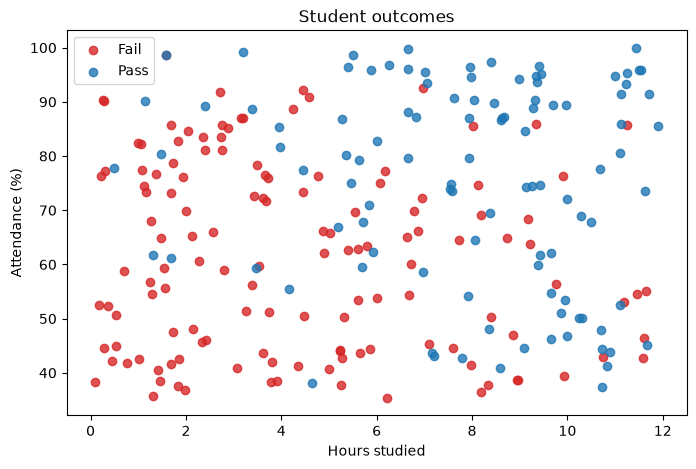

In [18]:
# Scatter plot: one colour per class
fig, ax = plt.subplots(figsize=(8, 5))
for label, name, colour in [(0, "Fail", "tab:red"), (1, "Pass", "tab:blue")]:
    subset = df[df["passed"] == label]
    ax.scatter(subset["study_hours"], subset["attendance"], label=name, color=colour, alpha=0.8)
ax.set_xlabel("Hours studied")
ax.set_ylabel("Attendance (%)")
ax.set_title("Student outcomes")
ax.legend()
plt.show()

## 4. Split into training and test sets

We fit each model on the **training set** and measure it on the **test set**: students the model has never seen. The gap between the two scores shows how well a model generalises.

In [19]:
X = df[["study_hours", "attendance"]]
y = df["passed"]

# 75% training, 25% test; stratify keeps the Pass/Fail ratio the same in both sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=RANDOM_STATE, stratify=y
)

print("Training rows:", len(X_train))
print("Test rows:", len(X_test))

Training rows: 180
Test rows: 60


## 5. Fit a small decision tree

A tree asks questions about one feature at a time. Each split divides the data into groups; each leaf gives a prediction.

Trees compare thresholds rather than distances, so **no feature scaling is needed**.

In [20]:
# max_depth limits how many questions the tree may ask in a row
tree = DecisionTreeClassifier(max_depth=3, random_state=RANDOM_STATE)
tree.fit(X_train, y_train)

print("Training accuracy:", round(tree.score(X_train, y_train), 2))
print("Test accuracy:", round(tree.score(X_test, y_test), 2))

Training accuracy: 0.79
Test accuracy: 0.75


### Read the tree

Each box shows:
- the **question** (e.g. `study_hours <= 4.6`): go left if true, right if false
- **gini**: how mixed the group is (0 = all one class, 0.5 = a 50/50 mix)
- **samples**: how many training students reach this box
- **value**: how many of them are [Fail, Pass]
- **class**: the majority class, which is the prediction at a leaf

The tree picks each question to make the groups below it as pure as possible (lowest size-weighted gini).

> **Which measure is used?** scikit-learn's default is `criterion="gini"` (Gini impurity). The alternative is `criterion="entropy"`.
> - **Gini** = the chance that a randomly chosen student in the box would be mislabelled if we guessed a label at random according to the box's Pass/Fail proportions.
> - **Entropy** measures "surprise" or disorder: how many yes/no questions you would need, on average, to work out a student's label.
>
> Both are 0 for a pure group and largest for a 50/50 mix, so in practice they usually choose very similar splits. Gini is the default because it is slightly cheaper to compute. You can try `DecisionTreeClassifier(criterion="entropy")` to compare.


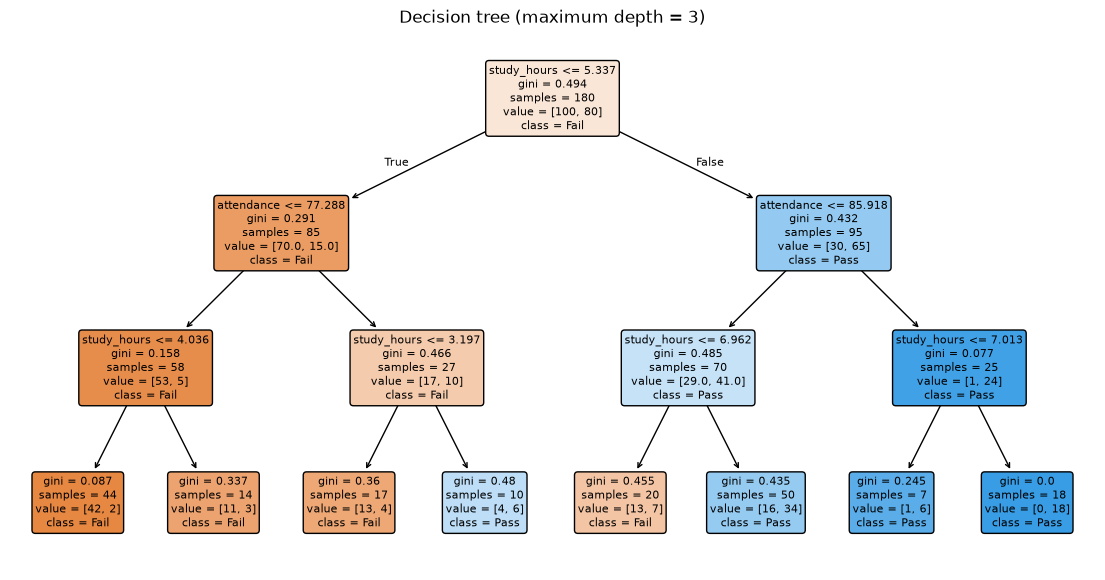

In [21]:
plt.figure(figsize=(14, 7))
plot_tree(
    tree,
    feature_names=X.columns,
    class_names=["Fail", "Pass"],
    filled=True,       # colour boxes by majority class
    rounded=True,
    proportion=False   # show counts, not fractions
)
plt.title("Decision tree (maximum depth = 3)")
plt.show()

## 6. Visualise the decision boundary

We predict the class for every point on a fine grid and colour the background by the prediction. Because each split asks about one feature, the regions are rectangles.

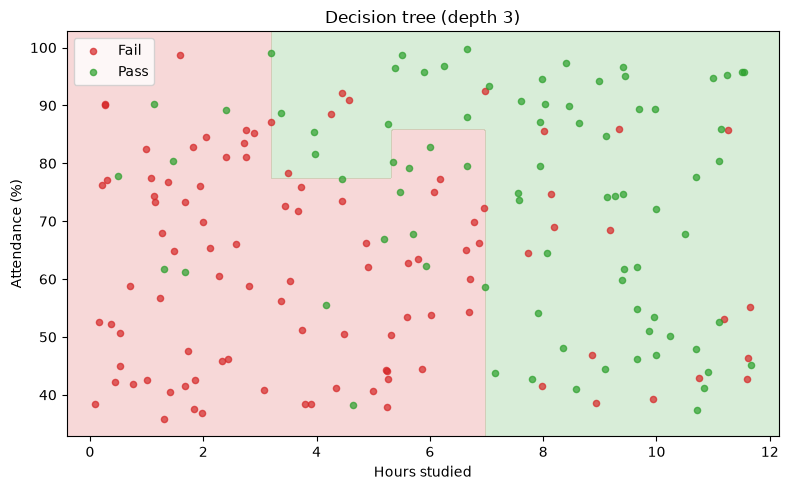

In [22]:
def plot_tree_boundary(model, X_plot, y_plot, title, ax):
    """Colour the feature space by the model's prediction and overlay the students."""
    # 1) Build a grid of (study_hours, attendance) points covering the data
    x_min, x_max = X_plot["study_hours"].min() - 0.5, X_plot["study_hours"].max() + 0.5
    y_min, y_max = X_plot["attendance"].min() - 3, X_plot["attendance"].max() + 3
    xx, yy = np.meshgrid(np.linspace(x_min, x_max, 250),
                         np.linspace(y_min, y_max, 250))
    grid = pd.DataFrame({"study_hours": xx.ravel(), "attendance": yy.ravel()})

    # 2) Predict a class for every grid point and colour the background (red = Fail, green = Pass)
    zz = model.predict(grid).reshape(xx.shape)
    ax.contourf(xx, yy, zz, alpha=0.18, levels=[-0.5, 0.5, 1.5],
                cmap=ListedColormap(["tab:red", "tab:green"]))

    # 3) Overlay the actual students
    for label, name, colour in [(0, "Fail", "tab:red"), (1, "Pass", "tab:green")]:
        subset = X_plot.loc[y_plot == label]
        ax.scatter(subset["study_hours"], subset["attendance"], label=name, color=colour, alpha=0.7, s=20)
    ax.set_xlabel("Hours studied")
    ax.set_ylabel("Attendance (%)")
    ax.set_title(title)

fig, ax = plt.subplots(figsize=(8, 5))
plot_tree_boundary(tree, X_train, y_train, "Decision tree (depth 3)", ax)
ax.legend()
plt.tight_layout()
plt.show()

## 7. Core investigation: tree depth

**Before running the code:** predict what will happen to training and test accuracy as depth increases.

In [23]:
# Fit one tree per depth and record both scores
results = []
for depth in range(1, 21):
    model = DecisionTreeClassifier(max_depth=depth, random_state=RANDOM_STATE)
    model.fit(X_train, y_train)
    results.append({
        "max_depth": depth,
        "Training accuracy": model.score(X_train, y_train),
        "Test accuracy": model.score(X_test, y_test),
        "Leaves": model.get_n_leaves()   # number of final groups = how complex the tree is
    })

tree_results = pd.DataFrame(results)
tree_results

,max_depth,Training accuracy,Test accuracy,Leaves
0,1,0.750000,0.716667,2
1,2,0.750000,0.716667,4
2,3,0.794444,0.750000,8
3,4,0.861111,0.683333,15
4,5,0.911111,0.700000,24
5,6,0.933333,0.733333,29
6,7,0.955556,0.683333,34
7,8,0.961111,0.716667,36
8,9,0.977778,0.683333,39
9,10,0.994444,0.700000,42


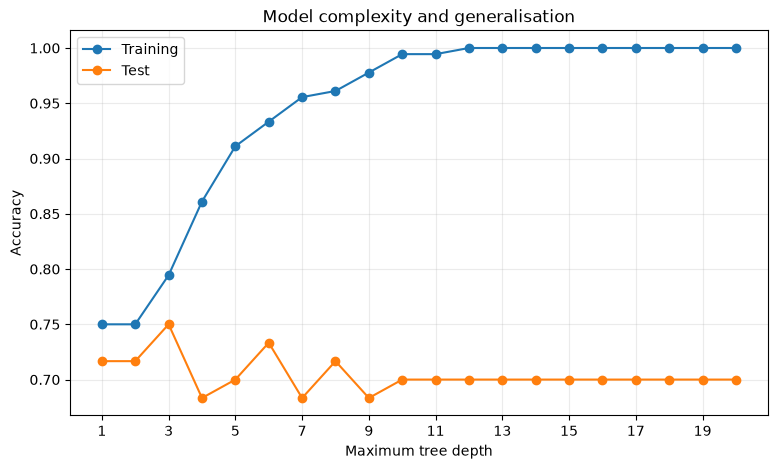

In [24]:
fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(tree_results["max_depth"], tree_results["Training accuracy"], marker="o", label="Training")
ax.plot(tree_results["max_depth"], tree_results["Test accuracy"], marker="o", label="Test")
ax.set_xlabel("Maximum tree depth")
ax.set_ylabel("Accuracy")
ax.set_title("Model complexity and generalisation")
ax.set_xticks(range(1, 21, 2))
ax.grid(alpha=0.25)
ax.legend()
plt.show()

### Interpret the results

- Training accuracy rises with depth because the tree can make ever more specific rules, until it memorises the training set (100%).
- Test accuracy peaks and then falls once the tree starts fitting noise: that is **overfitting**.
- Once the tree stops growing (the number of leaves stops changing), extra depth changes nothing.
- With only ~60 test students, the test curve is bumpy: one student is worth almost 2 percentage points.

In [25]:
best = tree_results.loc[tree_results["Test accuracy"].idxmax()]
print("Best depth on this test set:", int(best["max_depth"]))
print("Test accuracy:", round(best["Test accuracy"], 3))

Best depth on this test set: 3
Test accuracy: 0.75


> **Caveat:** choosing the depth by looking at the test set makes the test set less "unseen". Week 10 introduces cross-validation, the proper way to choose settings like this.

## Key takeaways

- Decision trees classify using a sequence of yes/no questions, one feature at a time.
- Tree boundaries are made from axis-aligned rectangles.
- Greater depth increases flexibility but can lead to overfitting.
- Compare training and test accuracy: a large gap signals overfitting.